# Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

from sklearn.metrics import confusion_matrix

# Read data

In [ ]:
train_data = pd.read_csv('/content/drive/MyDrive/ML/ML/تمرین سوم/Data/Adult_TrainDataset.csv')
train_data

,Age,Work_Class,Final_Weight,Education,Education-Number,Marital_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours-Per-Week,Native_Country,Income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [ ]:
test_data = pd.read_csv('/content/drive/MyDrive/ML/ML/تمرین سوم/Data/Adult_TestDataset.csv')
test_data

,Age,Work_Class,Final_Weight,Education,Education-Number,Marital_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours-Per-Week,Native_Country,Income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K.
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K.
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K.
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K.
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16276,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
16277,64,?,321403,HS-grad,9,Widowed,?,Other-relative,Black,Male,0,0,40,United-States,<=50K.
16278,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
16279,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.


In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               32561 non-null  int64 
 1   Work_Class        32561 non-null  object
 2   Final_Weight      32561 non-null  int64 
 3   Education         32561 non-null  object
 4   Education-Number  32561 non-null  int64 
 5   Marital_Status    32561 non-null  object
 6   Occupation        32561 non-null  object
 7   Relationship      32561 non-null  object
 8   Race              32561 non-null  object
 9   Sex               32561 non-null  object
 10  Capital_Gain      32561 non-null  int64 
 11  Capital_Loss      32561 non-null  int64 
 12  Hours-Per-Week    32561 non-null  int64 
 13  Native_Country    32561 non-null  object
 14  Income            32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16281 entries, 0 to 16280
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               16281 non-null  int64 
 1   Work_Class        16281 non-null  object
 2   Final_Weight      16281 non-null  int64 
 3   Education         16281 non-null  object
 4   Education-Number  16281 non-null  int64 
 5   Marital_Status    16281 non-null  object
 6   Occupation        16281 non-null  object
 7   Relationship      16281 non-null  object
 8   Race              16281 non-null  object
 9   Sex               16281 non-null  object
 10  Capital_Gain      16281 non-null  int64 
 11  Capital_Loss      16281 non-null  int64 
 12  Hours-Per-Week    16281 non-null  int64 
 13  Native_Country    16281 non-null  object
 14  Income            16281 non-null  object
dtypes: int64(6), object(9)
memory usage: 1.9+ MB


In [ ]:
#Get more index
train_data.describe()

,Age,Final_Weight,Education-Number,Capital_Gain,Capital_Loss,Hours-Per-Week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [ ]:
#Get more index
test_data.describe()

,Age,Final_Weight,Education-Number,Capital_Gain,Capital_Loss,Hours-Per-Week
count,16281.000000,1.628100e+04,16281.000000,16281.000000,16281.000000,16281.000000
mean,38.767459,1.894357e+05,10.072907,1081.905104,87.899269,40.392236
std,13.849187,1.057149e+05,2.567545,7583.935968,403.105286,12.479332
min,17.000000,1.349200e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.167360e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.778310e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.383840e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,3770.000000,99.000000


In [ ]:
#seperate
non_numeric_columns = train_data.select_dtypes(include=['object']).columns
numeric_columns = train_data.select_dtypes(exclude=['object']).columns
non_numeric_columns

Index(['Work_Class', 'Education', 'Marital_Status', 'Occupation',
       'Relationship', 'Race', 'Sex', 'Native_Country', 'Income'],
      dtype='object')

In [ ]:
numeric_columns

Index(['Age', 'Final_Weight', 'Education-Number', 'Capital_Gain',
       'Capital_Loss', 'Hours-Per-Week'],
      dtype='object')

In [ ]:
#print categorical columns values
print('workclass',train_data.Work_Class.unique())
print('education',train_data.Education.unique())
print('marital-status',train_data['Marital_Status'].unique())
print('occupation',train_data.Occupation.unique())
print('relationship',train_data.Relationship.unique())
print('race',train_data.Race.unique())
print('gender',train_data.Sex.unique())
print('native-country',train_data['Native_Country'].unique())
print('predclass',train_data.Income.unique())

workclass [' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov'
 ' ?' ' Self-emp-inc' ' Without-pay' ' Never-worked']
education [' Bachelors' ' HS-grad' ' 11th' ' Masters' ' 9th' ' Some-college'
 ' Assoc-acdm' ' Assoc-voc' ' 7th-8th' ' Doctorate' ' Prof-school'
 ' 5th-6th' ' 10th' ' 1st-4th' ' Preschool' ' 12th']
marital-status [' Never-married' ' Married-civ-spouse' ' Divorced'
 ' Married-spouse-absent' ' Separated' ' Married-AF-spouse' ' Widowed']
occupation [' Adm-clerical' ' Exec-managerial' ' Handlers-cleaners' ' Prof-specialty'
 ' Other-service' ' Sales' ' Craft-repair' ' Transport-moving'
 ' Farming-fishing' ' Machine-op-inspct' ' Tech-support' ' ?'
 ' Protective-serv' ' Armed-Forces' ' Priv-house-serv']
relationship [' Not-in-family' ' Husband' ' Wife' ' Own-child' ' Unmarried'
 ' Other-relative']
race [' White' ' Black' ' Asian-Pac-Islander' ' Amer-Indian-Eskimo' ' Other']
gender [' Male' ' Female']
native-country [' United-States' ' Cuba' ' Jamaica' ' India

# Preprocess data

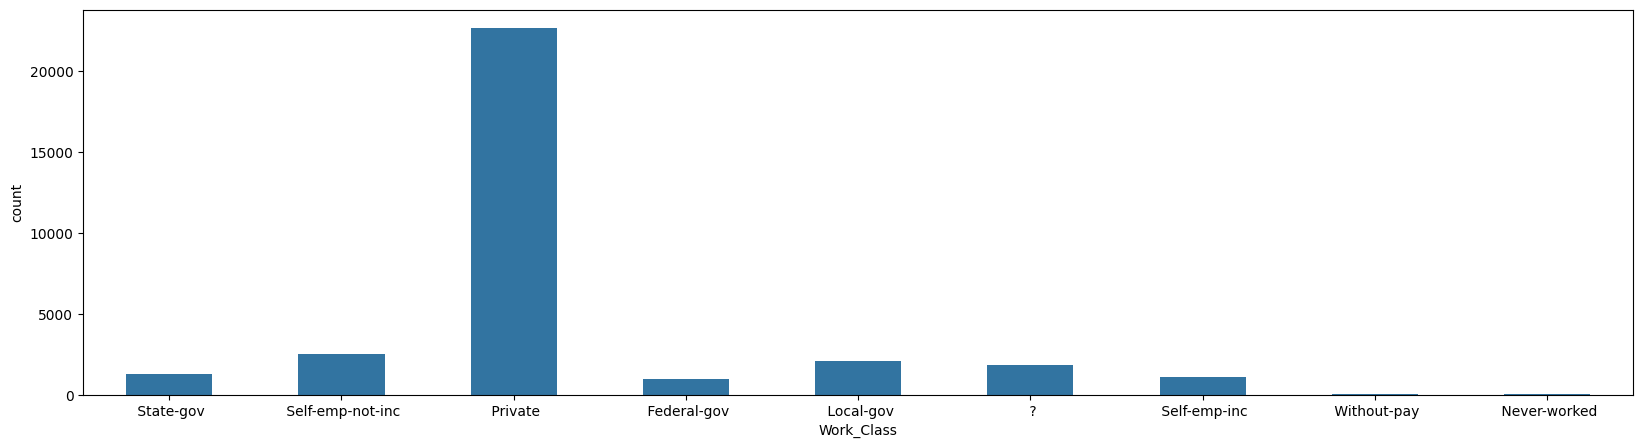

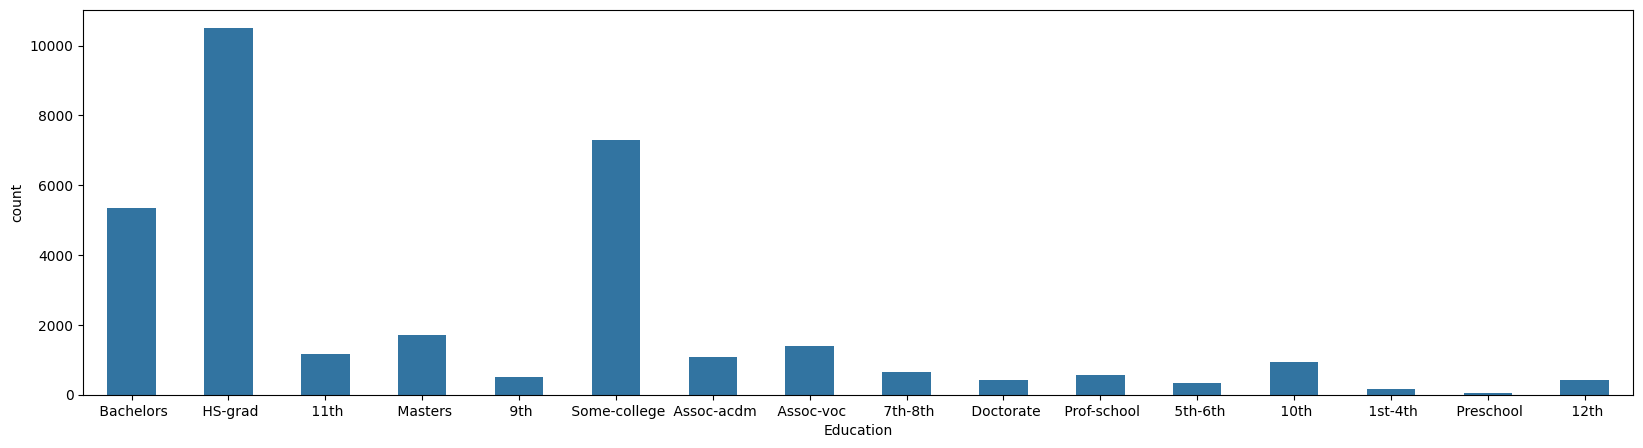

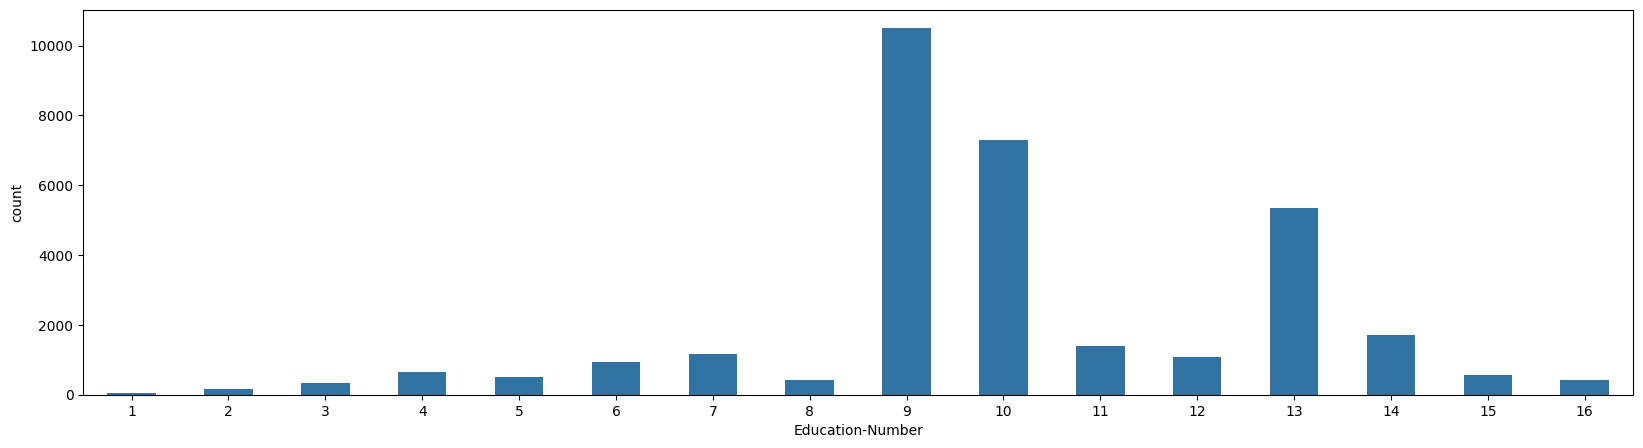

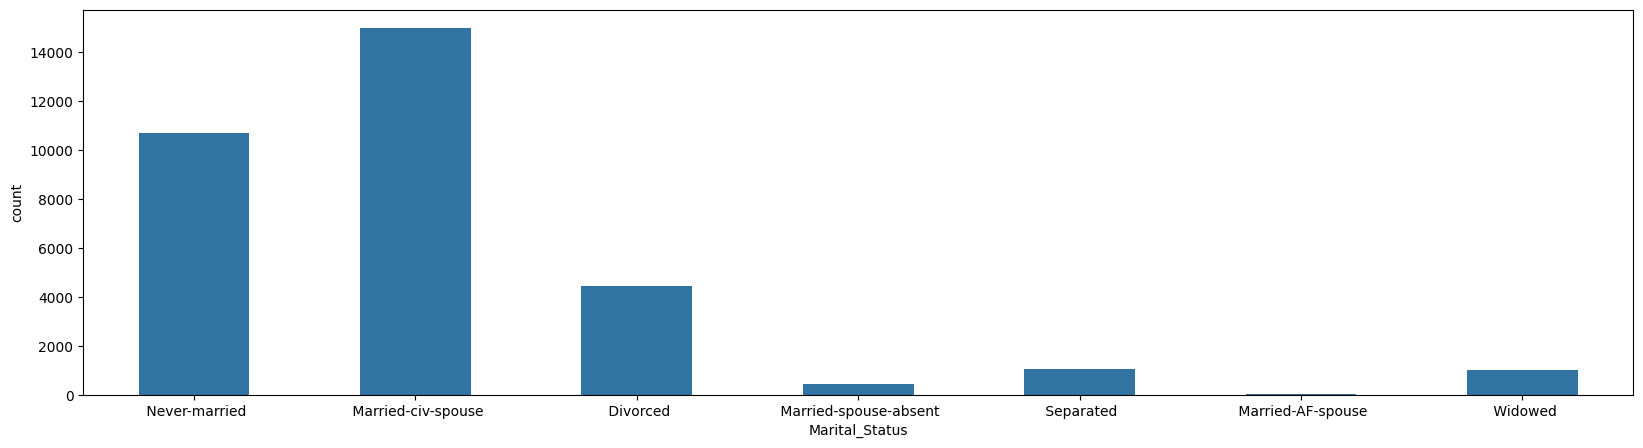

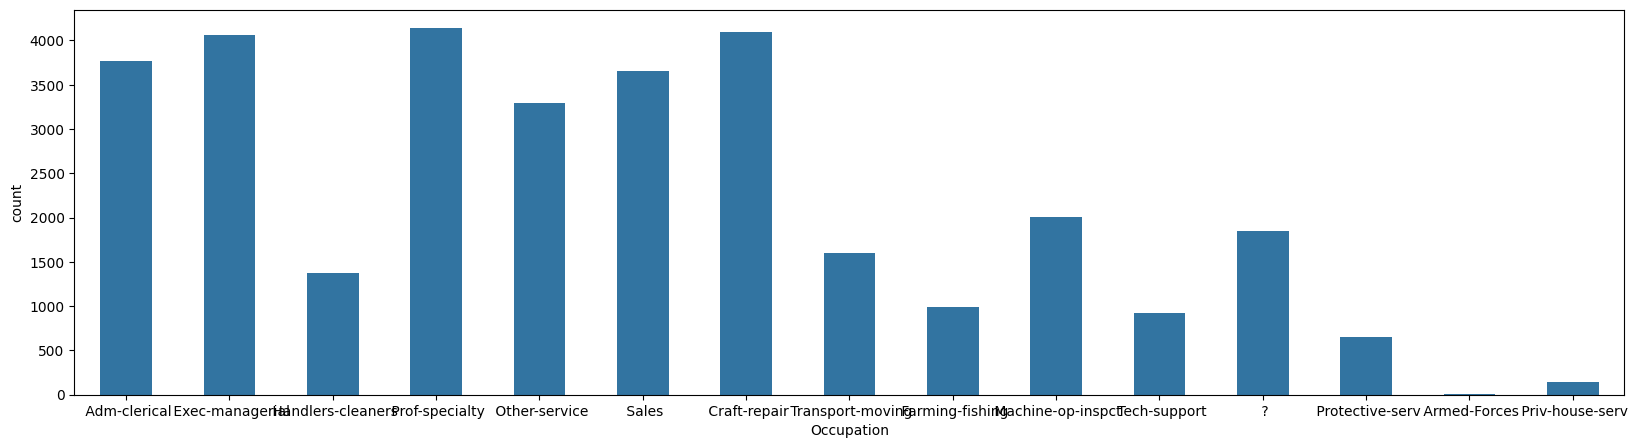

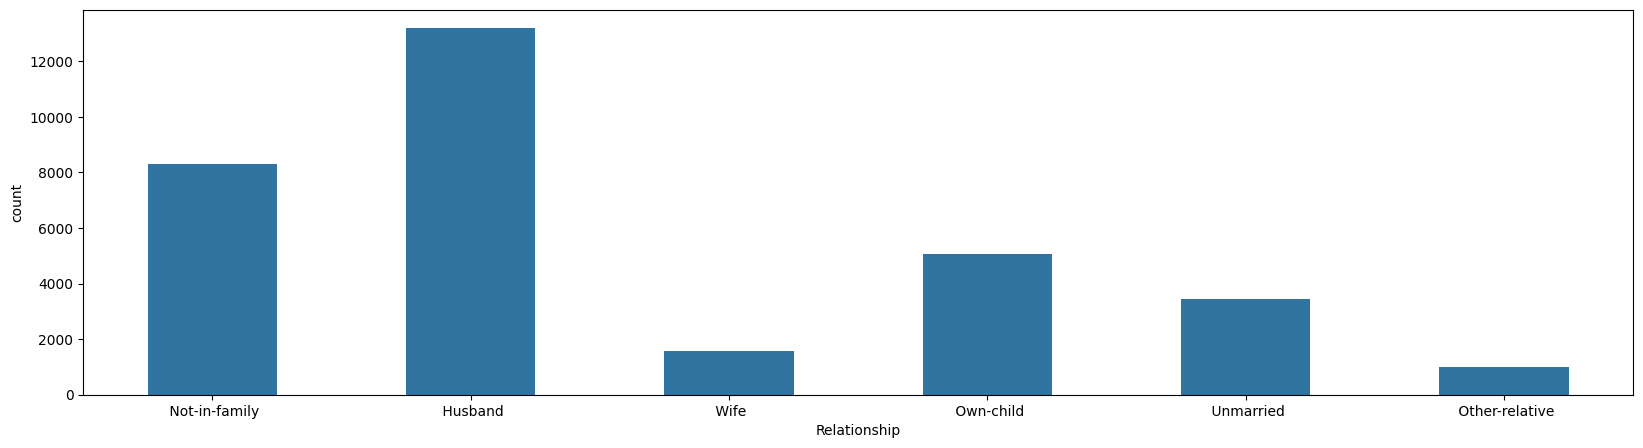

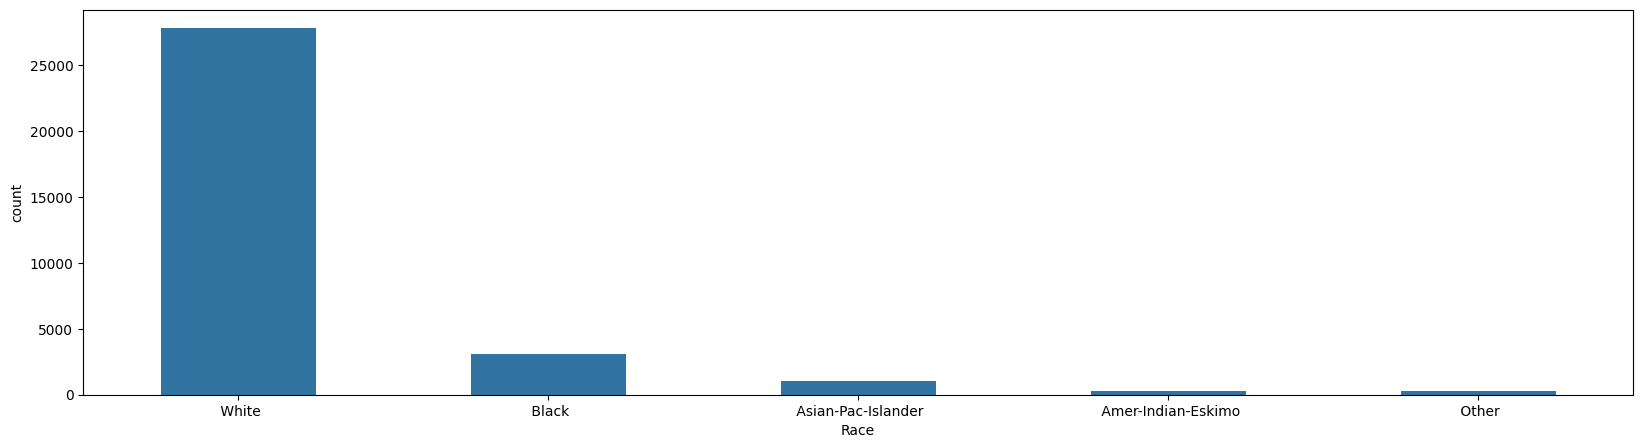

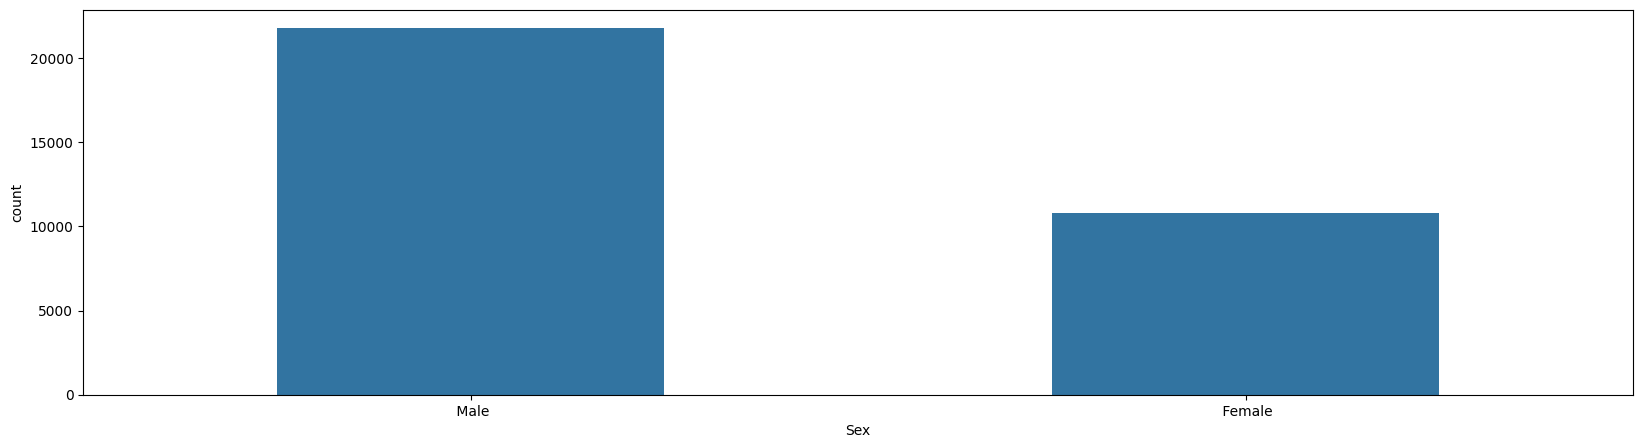

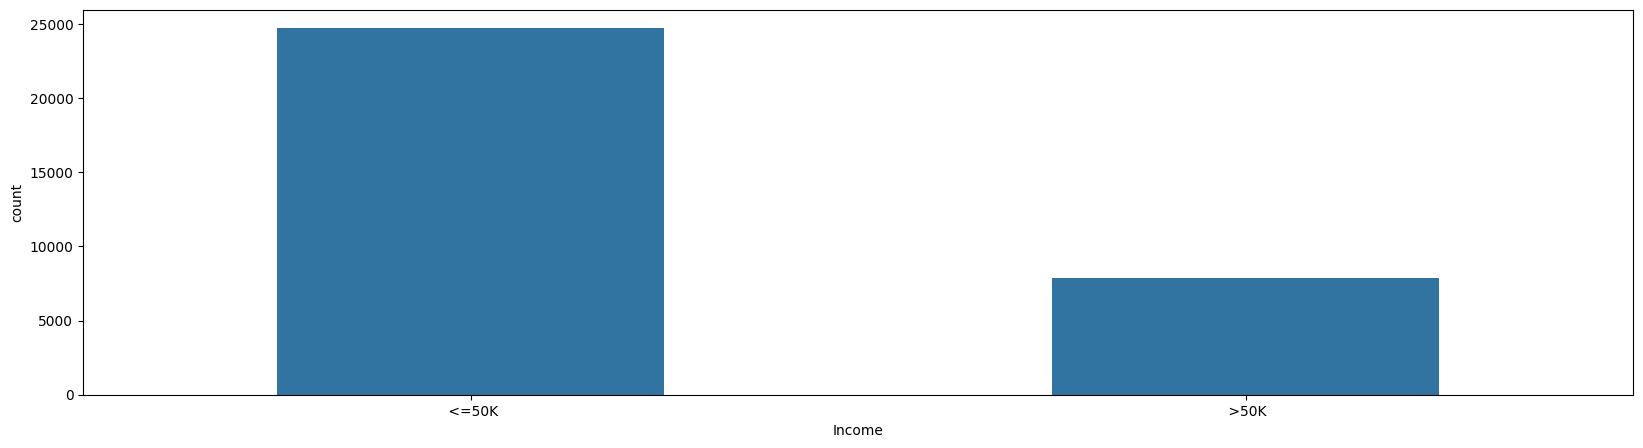

In [ ]:
#Plotting for columns with values ​​less than 20
for col in train_data.columns:
  if len(train_data[col].unique()) <20 :
    plt.figure(figsize=(20,5))
    sns.countplot(x=col, data=train_data,width=0.5)
plt.show()

In [ ]:
#duplicated
train_data.duplicated().sum()

np.int64(24)

In [ ]:
#remove duplicated row
train_data=train_data.drop_duplicates()

In [ ]:
#duplicated
test_data.duplicated().sum()

np.int64(5)

In [ ]:
#remove duplicated row
test_data=test_data.drop_duplicates()

In [ ]:
#replace ? to nan
#train_data.replace('?', np.nan, inplace=True)
train_data = train_data.replace(' ?', np.nan)

In [ ]:
#replace ? to nan
#test_data.replace('?', np.nan, inplace=True)
test_data = test_data.replace(' ?', np.nan)

In [ ]:
train_data.isna().sum()

,0
Age,0
Work_Class,1836
Final_Weight,0
Education,0
Education-Number,0
Marital_Status,0
Occupation,1843
Relationship,0
Race,0
Sex,0


In [ ]:
test_data.isna().sum()

,0
Age,0
Work_Class,963
Final_Weight,0
Education,0
Education-Number,0
Marital_Status,0
Occupation,966
Relationship,0
Race,0
Sex,0


In [ ]:
for col in ['Work_Class', 'Occupation', 'Native_Country']:
    mode_value = train_data[col].mode()[0]
    train_data[col] = train_data[col].fillna(mode_value)
    test_data[col] = test_data[col].fillna(mode_value)

In [ ]:
train_data.isna().sum()
test_data.isna().sum()

,0
Age,0
Work_Class,0
Final_Weight,0
Education,0
Education-Number,0
Marital_Status,0
Occupation,0
Relationship,0
Race,0
Sex,0


In [ ]:
train_data.columns

Index(['Age', 'Work_Class', 'Final_Weight', 'Education', 'Education-Number',
       'Marital_Status', 'Occupation', 'Relationship', 'Race', 'Sex',
       'Capital_Gain', 'Capital_Loss', 'Hours-Per-Week', 'Native_Country',
       'Income'],
      dtype='object')

In [ ]:
#seperate
train_non_numeric_columns = train_data.select_dtypes(include=['object']).columns
train_numeric_columns = train_data.select_dtypes(exclude=['object']).columns
train_non_numeric_columns

Index(['Work_Class', 'Education', 'Marital_Status', 'Occupation',
       'Relationship', 'Race', 'Sex', 'Native_Country', 'Income'],
      dtype='object')

In [ ]:
#seperate
test_non_numeric_columns = test_data.select_dtypes(include=['object']).columns
test_numeric_columns = test_data.select_dtypes(exclude=['object']).columns
test_non_numeric_columns

Index(['Work_Class', 'Education', 'Marital_Status', 'Occupation',
       'Relationship', 'Race', 'Sex', 'Native_Country', 'Income'],
      dtype='object')

In [ ]:
print(train_data['Income'].unique())
print(test_data['Income'].unique())

[' <=50K' ' >50K']
[' <=50K.' ' >50K.']


In [ ]:
train_data['Income'] = train_data['Income'].str.replace('.', '', regex=False)
test_data['Income'] = test_data['Income'].str.replace('.', '', regex=False)

In [ ]:
categorical_columns = train_non_numeric_columns.drop('Income')

# One-Hot Encoding
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_encoded = encoder.fit_transform(train_data[categorical_columns])
test_encoded = encoder.transform(test_data[categorical_columns])

# Convert to DataFrame
train_encoded = pd.DataFrame(
    train_encoded,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=train_data.index
)

test_encoded = pd.DataFrame(
    test_encoded,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=test_data.index
)

# Replace categorical columns
train_data = pd.concat(
    [train_data.drop(columns=categorical_columns), train_encoded], axis=1
)

test_data = pd.concat(
    [test_data.drop(columns=categorical_columns), test_encoded], axis=1
)

# Encode target column
lb = LabelEncoder()
train_data['Income'] = lb.fit_transform(train_data['Income'])
test_data['Income'] = lb.transform(test_data['Income'])

In [ ]:
train_data.head()

,Age,Final_Weight,Education-Number,Capital_Gain,Capital_Loss,Hours-Per-Week,Income,Work_Class_ Federal-gov,Work_Class_ Local-gov,Work_Class_ Never-worked,...,Native_Country_ Portugal,Native_Country_ Puerto-Rico,Native_Country_ Scotland,Native_Country_ South,Native_Country_ Taiwan,Native_Country_ Thailand,Native_Country_ Trinadad&Tobago,Native_Country_ United-States,Native_Country_ Vietnam,Native_Country_ Yugoslavia
0,39,77516,13,2174,0,40,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,50,83311,13,0,0,13,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,38,215646,9,0,0,40,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,53,234721,7,0,0,40,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,28,338409,13,0,0,40,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
test_data.head()

,Age,Final_Weight,Education-Number,Capital_Gain,Capital_Loss,Hours-Per-Week,Income,Work_Class_ Federal-gov,Work_Class_ Local-gov,Work_Class_ Never-worked,...,Native_Country_ Portugal,Native_Country_ Puerto-Rico,Native_Country_ Scotland,Native_Country_ South,Native_Country_ Taiwan,Native_Country_ Thailand,Native_Country_ Trinadad&Tobago,Native_Country_ United-States,Native_Country_ Vietnam,Native_Country_ Yugoslavia
0,25,226802,7,0,0,40,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,38,89814,9,0,0,50,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,28,336951,12,0,0,40,1,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,44,160323,10,7688,0,40,1,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,18,103497,10,0,0,30,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
print(train_data.dtypes)
print(test_data.dtypes)

Age                                  int64
Final_Weight                         int64
Education-Number                     int64
Capital_Gain                         int64
Capital_Loss                         int64
                                    ...   
Native_Country_ Thailand           float64
Native_Country_ Trinadad&Tobago    float64
Native_Country_ United-States      float64
Native_Country_ Vietnam            float64
Native_Country_ Yugoslavia         float64
Length: 106, dtype: object
Age                                  int64
Final_Weight                         int64
Education-Number                     int64
Capital_Gain                         int64
Capital_Loss                         int64
                                    ...   
Native_Country_ Thailand           float64
Native_Country_ Trinadad&Tobago    float64
Native_Country_ United-States      float64
Native_Country_ Vietnam            float64
Native_Country_ Yugoslavia         float64
Length: 106, dtype: object


In [ ]:
print(train_data.shape, test_data.shape)
print(train_data.isna().sum().sum())
print(test_data.isna().sum().sum())

(32537, 106) (16276, 106)
0
0


In [ ]:
# Recreate X and y
X_train = train_data.drop('Income', axis=1)
y_train = train_data['Income']

X_test = test_data.drop('Income', axis=1)
y_test = test_data['Income']

# Scale only numerical features
st = StandardScaler()

X_train[numeric_columns] = st.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = st.transform(X_test[numeric_columns])

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(X_train.mean(axis=0)[:6])
print(X_train.std(axis=0)[:6])

(32537, 105)
(16276, 105)
Age                -7.665135e-17
Final_Weight       -1.249133e-16
Education-Number    2.882615e-17
Capital_Gain        1.790715e-17
Capital_Loss        2.183799e-19
Hours-Per-Week     -6.616911e-17
dtype: float64
Age                 1.000015
Final_Weight        1.000015
Education-Number    1.000015
Capital_Gain        1.000015
Capital_Loss        1.000015
Hours-Per-Week      1.000015
dtype: float64


# KNN

In [ ]:
#creat model
knn=KNeighborsClassifier(n_neighbors=9)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=9)

In [ ]:
#pred
y_pred=knn.predict(X_test)
y_pred

array([0, 0, 1, ..., 1, 0, 1], shape=(16276,))

In [ ]:
#Acuracy
from sklearn import metrics
print("Train set Accuracy: ", metrics.accuracy_score(y_train, knn.predict(X_train)))
print("Test set Accuracy: ", metrics.accuracy_score(y_test, y_pred))

Train set Accuracy:  0.8687647908534899
Test set Accuracy:  0.8398869501105923


In [ ]:
#mae
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_test, y_pred)

0.16011304988940772

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[11357  1073]
 [ 1533  2313]]


In [ ]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.91      0.90     12430
           1       0.68      0.60      0.64      3846

    accuracy                           0.84     16276
   macro avg       0.78      0.76      0.77     16276
weighted avg       0.83      0.84      0.84     16276



## Hyper parameter tuning for KNN

In [ ]:
from sklearn import metrics

In [ ]:
#find best k
k_range = range(1, 41)
k_scores = []
train_accuracy = []
test_accuracy = []
train_error = []
test_error = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    #scores = cross_val_score(knn, X, y, cv=10, scoring='accuracy')
    scores = cross_val_score(knn, X_train, y_train, cv=10, scoring='accuracy')
    k_scores.append(scores.mean())
    #pred
    knn.fit(X_train, y_train)
    y_pred=knn.predict(X_test)
    train_accuracy.append(metrics.accuracy_score(y_train, knn.predict(X_train)))
    test_accuracy.append(metrics.accuracy_score(y_test, y_pred))
    train_error.append(1 - train_accuracy[-1])
    test_error.append(1 - test_accuracy[-1])

print(k_scores)

[np.float64(0.8009651815892701), np.float64(0.8179921007151263), np.float64(0.8251533027713439), np.float64(0.832314145837864), np.float64(0.8334515196695179), np.float64(0.8358179325178725), np.float64(0.836063934931417), np.float64(0.8378771729977018), np.float64(0.8405509849449168), np.float64(0.841473031087941), np.float64(0.8417189106892206), np.float64(0.8412887465610204), np.float64(0.8422414390876674), np.float64(0.8415040553554556), np.float64(0.8417806947055254), np.float64(0.8415040270141636), np.float64(0.8430407768839355), np.float64(0.8429486393440238), np.float64(0.8435633525178687), np.float64(0.8434710732714977), np.float64(0.8434710827185949), np.float64(0.8435939705601998), np.float64(0.8443315715756492), np.float64(0.8433173406572271), np.float64(0.8440856447388831), np.float64(0.8436246641793088), np.float64(0.8440241346883998), np.float64(0.8433787751309321), np.float64(0.8429177284416767), np.float64(0.8425181256732237), np.float64(0.8432865431200476), np.float64

In [ ]:
print(np.argmax(k_scores))
print(max(k_scores))

22
0.8443315715756492


In [ ]:
best_k = k_range[np.argmax(k_scores)]
print("Best K:", best_k)

Best K: 23


In [ ]:
#creat model
knn=KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=23)

In [ ]:
#pred
y_pred=knn.predict(X_test)
y_pred

array([0, 0, 1, ..., 1, 0, 1], shape=(16276,))

In [ ]:
#Acuracy
from sklearn import metrics
print("Train set Accuracy: ", metrics.accuracy_score(y_train, knn.predict(X_train)))
print("Test set Accuracy: ", metrics.accuracy_score(y_test, y_pred))

Train set Accuracy:  0.8556720041798568
Test set Accuracy:  0.8456008847382649


In [ ]:
#mae
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_test, y_pred)

0.15439911526173508

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[11421  1009]
 [ 1504  2342]]


In [ ]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90     12430
           1       0.70      0.61      0.65      3846

    accuracy                           0.85     16276
   macro avg       0.79      0.76      0.78     16276
weighted avg       0.84      0.85      0.84     16276



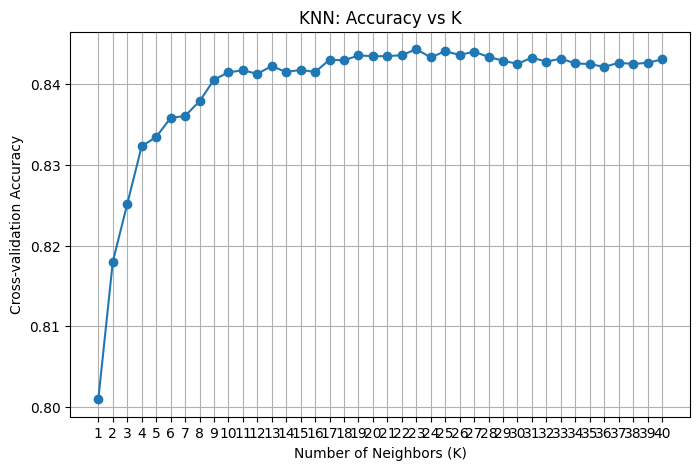

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(k_range, k_scores, marker='o')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Cross-validation Accuracy')
plt.title('KNN: Accuracy vs K')
plt.xticks(k_range)
plt.grid()
plt.show()

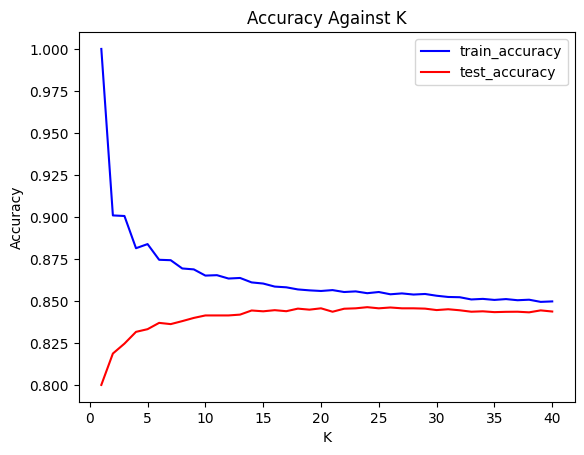

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
x = k_range
y1 = train_accuracy
y2 = test_accuracy
plt.plot(x, y1, label='train_accuracy', color='blue')
plt.plot(x, y2, label='test_accuracy', color='red')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('Accuracy Against K')
plt.legend()
plt.show()

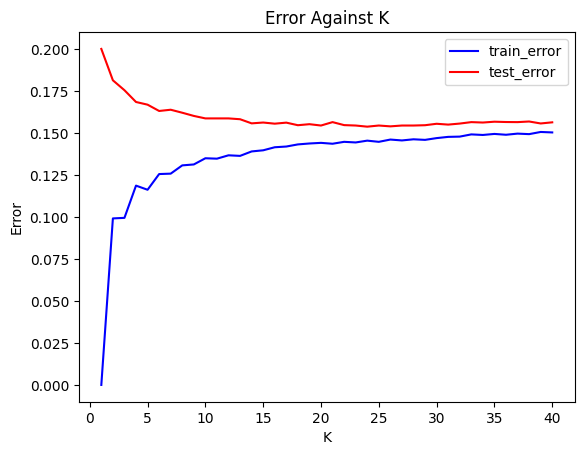

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
x = k_range
y1 = train_error
y2 = test_error
plt.plot(x, y1, label='train_error', color='blue')
plt.plot(x, y2, label='test_error', color='red')
plt.xlabel('K')
plt.ylabel('Error')
plt.title('Error Against K')
plt.legend()
plt.show()

# SVM

SVC with RBF

In [ ]:
# import SVC classifier
from sklearn.svm import SVC
# import metrics to compute accuracy
from sklearn.metrics import accuracy_score

# instantiate classifier with default hyperparameters
svc=SVC()
# fit classifier to training set
svc.fit(X_train,y_train)
# make predictions on test set
y_pred=svc.predict(X_test)

# compute and print accuracy score
print('Model accuracy score with default hyperparameters: {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

Model accuracy score with default hyperparameters: 0.8582


In [ ]:
# print the scores on training and test set
print('Training set score: {:.4f}'.format(svc.score(X_train, y_train)))
print('Test set score: {:.4f}'.format(svc.score(X_test, y_test)))

Training set score: 0.8662
Test set score: 0.8582


In [ ]:
from sklearn.metrics import classification_report

In [ ]:
print(accuracy_score(y_train, svc.predict(X_train)))
print(accuracy_score(y_test, svc.predict(X_test)))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.8661523803669668
0.8581961169820594
[[11716   714]
 [ 1594  2252]]
              precision    recall  f1-score   support

           0       0.88      0.94      0.91     12430
           1       0.76      0.59      0.66      3846

    accuracy                           0.86     16276
   macro avg       0.82      0.76      0.79     16276
weighted avg       0.85      0.86      0.85     16276



## Hyper parameter tuning for SVC

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, accuracy_score, mean_squared_error, r2_score, roc_auc_score, roc_curve, classification_report

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

svc = SVC()

parameter = {
    'C': [0.1, 1, 10],
    'gamma': [0.001, 0.01, 0.1]
}

random_search = RandomizedSearchCV(
    estimator=svc,
    param_distributions=parameter,
    n_iter=8,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print('Best Parameters:', random_search.best_params_)
print('Best Score:', random_search.best_score_)

Best Parameters: {'gamma': 0.1, 'C': 1}
Best Score: 0.856962944996241


In [ ]:
# best_parameter
random_search.best_params_

{'gamma': 0.1, 'C': 1}

In [ ]:
random_search.best_score_

np.float64(0.856962944996241)

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, mean_squared_error, r2_score, roc_auc_score, roc_curve, classification_report

In [ ]:
svc = SVC(C=1, gamma = 0.1)
svc.fit(X_train, y_train)
y_pred = svc.predict(X_test)
print(accuracy_score(y_train, svc.predict(X_train)))
svc_acc = accuracy_score(y_test, svc.predict(X_test))
print(accuracy_score(y_test, svc.predict(X_test)))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.8697482865660633
0.857704595723765
[[11687   743]
 [ 1573  2273]]
              precision    recall  f1-score   support

           0       0.88      0.94      0.91     12430
           1       0.75      0.59      0.66      3846

    accuracy                           0.86     16276
   macro avg       0.82      0.77      0.79     16276
weighted avg       0.85      0.86      0.85     16276



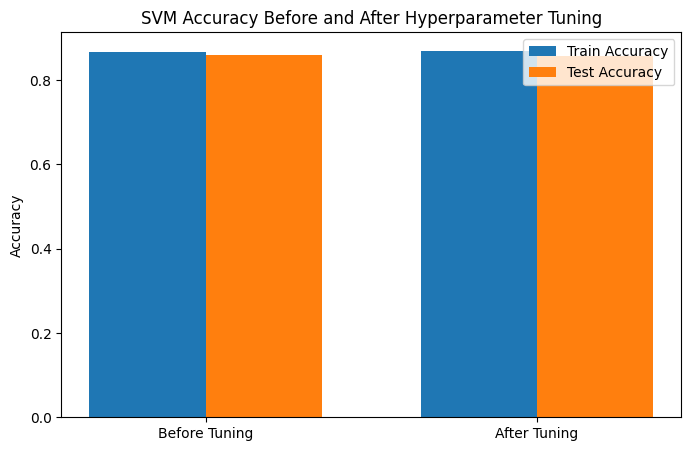

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Before Tuning', 'After Tuning']

train_acc = [0.8662, 0.8697]
test_acc = [0.8582, 0.8577]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, train_acc, width, label='Train Accuracy')
plt.bar(x + width/2, test_acc, width, label='Test Accuracy')

plt.xticks(x, models)
plt.ylabel('Accuracy')
plt.title('SVM Accuracy Before and After Hyperparameter Tuning')
plt.legend()
plt.show()

# Naive Bayes

In [ ]:
# train a Gaussian Naive Bayes classifier on the training set
from sklearn.naive_bayes import GaussianNB

# instantiate the model
gnb = GaussianNB()
# fit the model
gnb.fit(X_train, y_train)

GaussianNB()

In [ ]:
y_pred = gnb.predict(X_test)
y_pred

array([0, 1, 1, ..., 1, 0, 1], shape=(16276,))

In [ ]:
from sklearn.metrics import accuracy_score
print('Model accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

Model accuracy score: 0.5514


In [ ]:
y_pred_train = gnb.predict(X_train)
y_pred_train

array([1, 1, 1, ..., 0, 0, 1], shape=(32537,))

In [ ]:
print('Training-set accuracy score: {0:0.4f}'. format(accuracy_score(y_train, y_pred_train)))

Training-set accuracy score: 0.5571


In [ ]:
# print the scores on training and test set
print('Training set score: {:.4f}'.format(gnb.score(X_train, y_train)))
print('Test set score: {:.4f}'.format(gnb.score(X_test, y_test)))

Training set score: 0.5571
Test set score: 0.5514


In [ ]:
# Print the Confusion Matrix and slice it into four pieces
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix\n\n', cm)


Confusion matrix

 [[5368 7062]
 [ 240 3606]]


<Axes: >

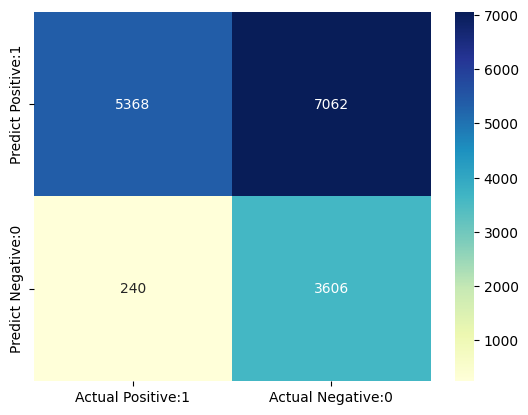

In [ ]:
# visualize confusion matrix with seaborn heatmap
cm_matrix = pd.DataFrame(data=cm, columns=['Actual Positive:1', 'Actual Negative:0'],
                                 index=['Predict Positive:1', 'Predict Negative:0'])
sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.43      0.60     12430
           1       0.34      0.94      0.50      3846

    accuracy                           0.55     16276
   macro avg       0.65      0.68      0.55     16276
weighted avg       0.81      0.55      0.57     16276



## Hyper parameter tuning for Naive Bayes

In [ ]:
nb_classifier = GaussianNB()

params_NB = {'var_smoothing': np.logspace(0,-9, num=100)}
gs_NB = GridSearchCV(estimator=nb_classifier,
                 param_grid=params_NB,
                 verbose=1,
                 scoring='accuracy')
gs_NB.fit(X_train, y_train)

best_parameters = gs_NB.best_params_
print('best_parameters: ', best_parameters)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
best_parameters:  {'var_smoothing': np.float64(0.3511191734215131)}


Model accuracy score: 0.8283
Training-set accuracy score: 0.8315
Training set score: 0.8315
Test set score: 0.8283
Confusion matrix

 [[11324  1106]
 [ 1689  2157]]
              precision    recall  f1-score   support

           0       0.87      0.91      0.89     12430
           1       0.66      0.56      0.61      3846

    accuracy                           0.83     16276
   macro avg       0.77      0.74      0.75     16276
weighted avg       0.82      0.83      0.82     16276



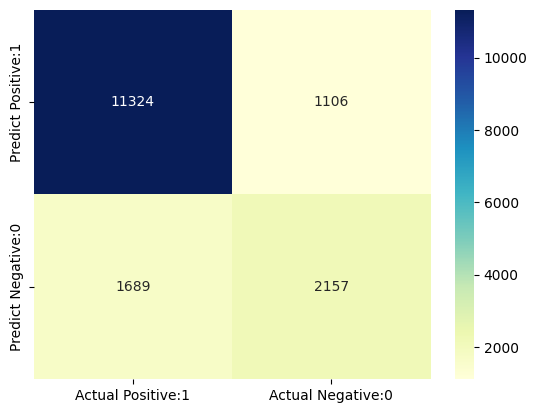

In [ ]:
# train a Gaussian Naive Bayes classifier on the training set
from sklearn.naive_bayes import GaussianNB

# instantiate the model
gnb = GaussianNB(var_smoothing = np.float64(0.3511191734215131))
# fit the model
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)


from sklearn.metrics import accuracy_score
print('Model accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred)))
y_pred_train = gnb.predict(X_train)
y_pred_train
print('Training-set accuracy score: {0:0.4f}'. format(accuracy_score(y_train, y_pred_train)))

# print the scores on training and test set
print('Training set score: {:.4f}'.format(gnb.score(X_train, y_train)))
print('Test set score: {:.4f}'.format(gnb.score(X_test, y_test)))

# Print the Confusion Matrix and slice it into four pieces
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

print('Confusion matrix\n\n', cm)
# visualize confusion matrix with seaborn heatmap
cm_matrix = pd.DataFrame(data=cm, columns=['Actual Positive:1', 'Actual Negative:0'],
                                 index=['Predict Positive:1', 'Predict Negative:0'])
sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

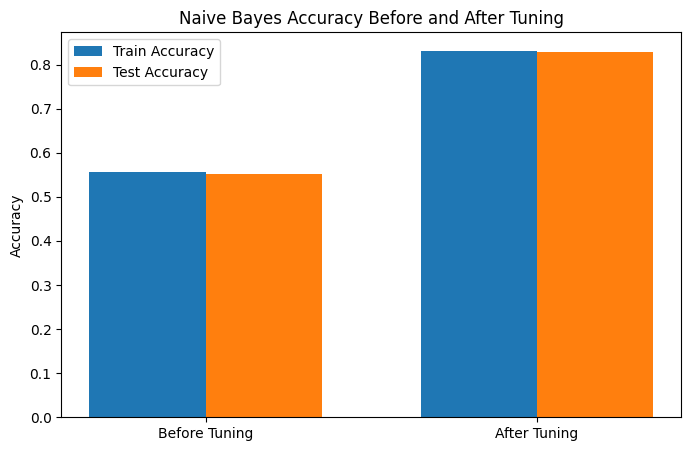

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Before Tuning', 'After Tuning']
train_acc = [0.5571, 0.8315]
test_acc = [0.5514, 0.8283]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, train_acc, width, label='Train Accuracy')
plt.bar(x + width/2, test_acc, width, label='Test Accuracy')

plt.xticks(x, models)
plt.ylabel('Accuracy')
plt.title('Naive Bayes Accuracy Before and After Tuning')
plt.legend()
plt.show()

# Ensemble Models

Mojarity Voting

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report

# Define the three models
# we will use in our ensemble
first_classifier = KNeighborsClassifier(n_neighbors=23)
second_classifier = SVC(C=1, gamma = 0.1)
third_classifier = GaussianNB(var_smoothing = np.float64(0.3511191734215131))

# Define the ensemble model
ensemble = VotingClassifier(estimators=[
    ("KNeighborsClassifier", first_classifier),
    ("support vector machine", second_classifier),
    ("GaussianNB", third_classifier)
], voting="hard")


# Train the ensemble
ensemble.fit(X_train, y_train)

# Use the ensemble to make predictions
predictions = ensemble.predict(X_test)
# Generate the classification report
report = classification_report(y_test, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.88      0.93      0.91     12430
           1       0.73      0.59      0.65      3846

    accuracy                           0.85     16276
   macro avg       0.80      0.76      0.78     16276
weighted avg       0.84      0.85      0.85     16276



In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report

# Define the three models
# we will use in our ensemble
first_classifier = KNeighborsClassifier(n_neighbors=23)
second_classifier = SVC(C=1, gamma = 0.1,probability=True)
third_classifier = GaussianNB(var_smoothing = np.float64(0.3511191734215131))

# Define the ensemble model
ensemble = VotingClassifier(estimators=[
    ("KNeighborsClassifier", first_classifier),
    ("support vector machine", second_classifier),
    ("GaussianNB", third_classifier)
], voting="soft")



# Train the ensemble
ensemble.fit(X_train, y_train)

# Use the ensemble to make predictions
predictions = ensemble.predict(X_test)
# Generate the classification report
report = classification_report(y_test, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.88      0.93      0.90     12430
           1       0.73      0.58      0.64      3846

    accuracy                           0.85     16276
   macro avg       0.80      0.76      0.77     16276
weighted avg       0.84      0.85      0.84     16276



Averaging Method

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model1 = KNeighborsClassifier(n_neighbors=23)
model2 = SVC(C=1, gamma = 0.1)
model3 = GaussianNB(var_smoothing = np.float64(0.3511191734215131))

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)
pred3 = model3.predict(X_test)


y_pred = (pred1 + pred2 + pred3) / 3

r2 = r2_score(y_test, y_pred)

print("R2 Score :", r2)

# Generate the classification report
report = classification_report(y_test, y_pred.round())
print(report)

R2 Score : 0.2761044189868068
              precision    recall  f1-score   support

           0       0.88      0.93      0.91     12430
           1       0.73      0.59      0.65      3846

    accuracy                           0.85     16276
   macro avg       0.80      0.76      0.78     16276
weighted avg       0.84      0.85      0.85     16276



# Final Model Comparison

### 1. Comparison of Tuned Models

| Model | Train Accuracy | Test Accuracy | Precision (Class 1) | Recall (Class 1) | F1-score (Class 1) |
|---|---:|---:|---:|---:|---:|
| KNN (K=23) | 85.57% | 84.56% | 70% | 61% | 65% |
| SVM (RBF) | 86.97% | 85.77% | 75% | 59% | 66% |
| Gaussian Naive Bayes | 83.15% | 82.83% | 66% | 56% | 61% |

### 2. Comparison of Ensemble Methods

| Method | Accuracy | Precision (Class 1) | Recall (Class 1) | F1-score (Class 1) |
|---|---:|---:|---:|---:|
| Hard Voting | 85% | 73% | 59% | 65% |
| Soft Voting | 85% | 73% | 58% | 64% |
| Averaging | 85% | 73% | 59% | 65% |

### 3. Final Conclusion

- **SVM** achieved the best overall performance, with a test accuracy of 85.77% and an F1-score of 66% for the positive class (`>50K`).
- **KNN** achieved a test accuracy of 84.56%, while **Gaussian Naive Bayes** achieved 82.83%.
- Hyperparameter tuning significantly improved Naive Bayes performance, whereas the improvements for KNN and SVM were relatively small.
- Among the ensemble methods, Hard Voting and Soft Voting achieved similar results. However, neither outperformed the best individual model (SVM).
- The Averaging method produced the same results as Hard Voting because averaging binary class predictions and rounding them is equivalent to majority voting when using three classifiers.

Overall, SVM provided the best performance among the evaluated models. However, all models showed relatively weaker performance in identifying individuals with income above $50K, suggesting that further improvements in minority-class prediction could be explored.